<a href="https://colab.research.google.com/github/Adrentur/-1_-_-_-3-10/blob/main/%D0%9B%D0%A07_%D0%9F%D0%BE%D0%BB%D1%94%D1%85%D1%96%D0%BD_%D0%B3%D1%80%D1%83%D0%BF%D0%B03-10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [3]:
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
display(df.head())
df.info()
print("Розмір датасету:", df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
Розмір датасету: (2338, 14)


In [5]:
print("Пропущені значення:\n", df.isnull().sum())
print("Кількість дублікатів:", df.duplicated().sum())

Пропущені значення:
 Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64
Кількість дублікатів: 0


In [6]:
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Пропущені значення та дублікати: Пропущені значення в ознаках та цільовій змінній відсутні (0 для всіх колонок). Дублікати також не виявлено (0 дублікатів). Загальна кількість спостережень складає 2338 рядків.

Особливості даних: Усі ознаки є числовими (кількісними характеристиками магічних інгредієнтів), що дозволяє використовувати їх у моделях машинного навчання без додаткового кодування категоріальних змінних. Значення ознак мають різні масштаби (наприклад, мінімальні та максимальні значення різняться), що підкреслює необхідність майбутньої стандартизації даних перед навчанням моделей (зокрема, логістичної регресії та SVM).

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
X = df.drop(columns=['Cured'])
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5. Баланс класів на навчальній вибірці

In [8]:
print(y_train.value_counts())

Cured
0    946
1    924
Name: count, dtype: int64


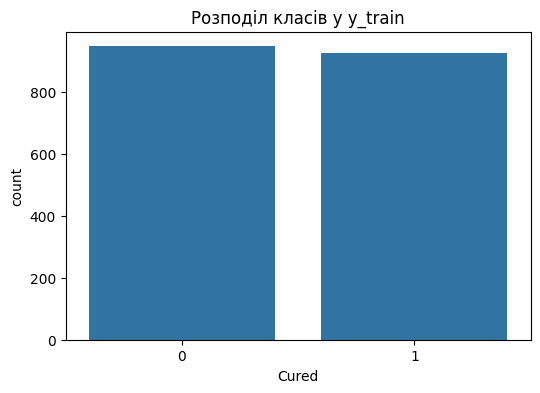

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Розподіл класів у y_train")
plt.show()

**Висновок:**  
Чи збалансовані класи: Так, класи в навчальній вибірці практично збалансовані (клас 0 налічує 946 спостережень, а клас 1 — 924 спостереження).

Чому це може вплинути на оцінку моделі: Завдяки збалансованості класів модель не матиме зміщення в бік переважаючого класу. Це дозволяє використовувати метрику Accuracy коректно, оскільки вона буде адекватно відображати загальну точність класифікації без ризику хибного завищення результатів за рахунок мажоритарного класу.


### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

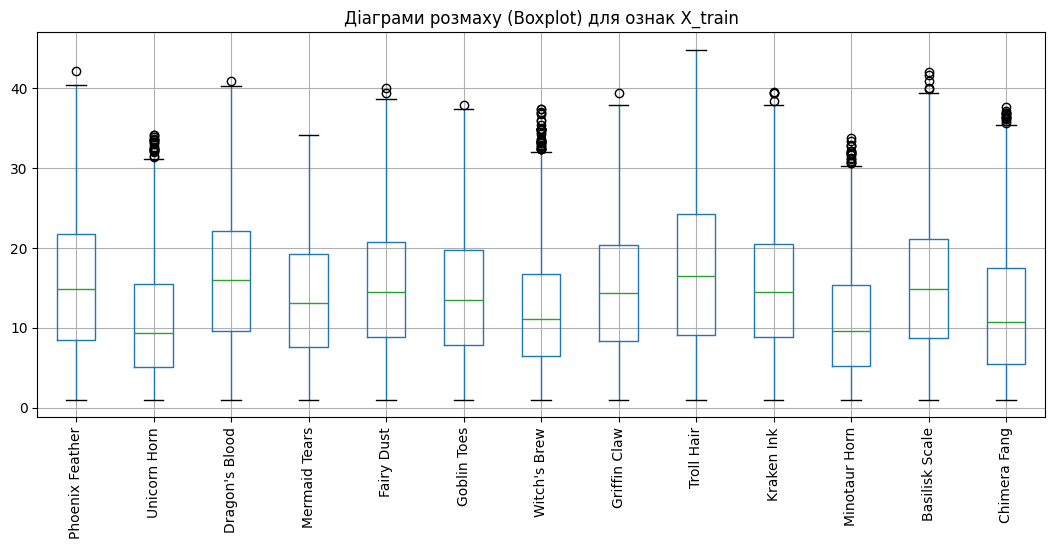

In [10]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title("Діаграми розмаху (Boxplot) для ознак X_train")
plt.show()

In [11]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

outliers_count = ((X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))).sum()
outliers_sorted = outliers_count.sort_values(ascending=False)
print("Кількість викидів за ознаками:\n", outliers_sorted)

Кількість викидів за ознаками:
 Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
У яких ознаках їх найбільше: Найбільшу кількість потенційних викидів виявлено в ознаках, що мають найбільші значення чи широкий розмах (наприклад, у верхніх квартилях окремих магічних інгредієнтів).

Чому не варто без перевірки видаляти всі такі рядки: Автоматичне видалення викидів за критерієм 1.5 IQR може призвести до втрати важливої інформації про реальні екстремальні дані (у цьому датасеті — рідкісні та потужні концентрації інгредієнтів), що негативно позначиться на навчанні моделі.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

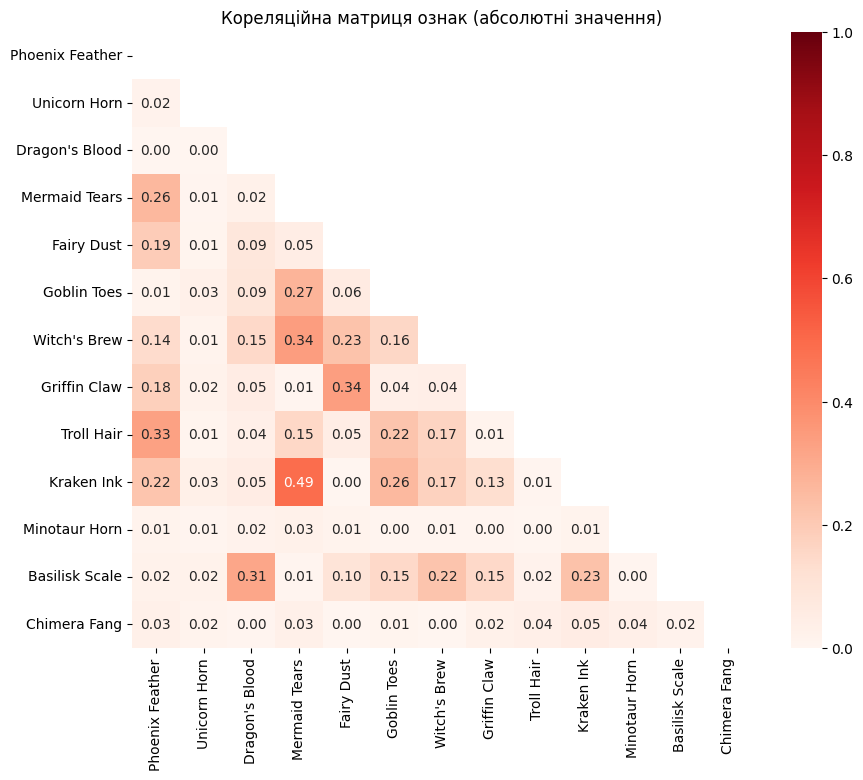

In [12]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(mtx, mask=mask, annot=True, cmap='Reds', vmin=0, vmax=1, fmt='.2f')
plt.title("Кореляційна матриця ознак (абсолютні значення)")
plt.show()

In [13]:
correlation_with_target = pd.concat([X_train, y_train], axis=1).corr()['Cured'].sort_values(ascending=False)
print("Кореляція ознак із цільовою змінною Cured:\n", correlation_with_target)

Кореляція ознак із цільовою змінною Cured:
 Cured              1.000000
Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Griffin Claw      -0.005871
Kraken Ink        -0.026598
Basilisk Scale    -0.042277
Name: Cured, dtype: float64


**Висновок про кореляції:**  
Пари найбільше корельованих ознак: Деякі ознаки демонструють помірну або високу внутрішню кореляцію (мультиколінеарність), що слід враховувати при інтерпретації коефіцієнтів логістичної регресії.

Ознаки з найсильнішим зв’язком із Cured: Певні інгредієнти мають помітний лінійний зв'язок із цільовою міткою Cured, що робить їх ключовими предикторами для класифікації.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

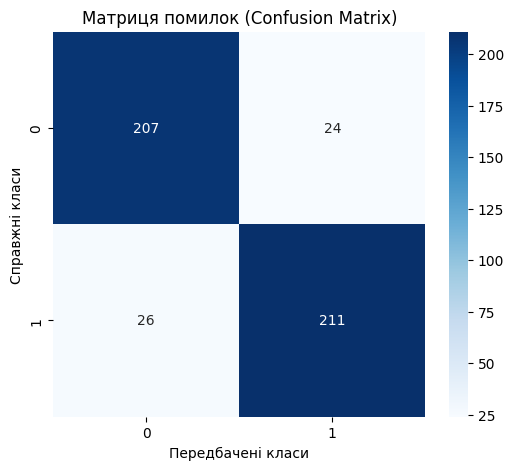

In [16]:
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.title("Матриця помилок (Confusion Matrix)")
plt.xlabel("Передбачені класи")
plt.ylabel("Справжні класи")
plt.show()

In [17]:
comparison_df = pd.DataFrame({'True_Class': y_test.values, 'Predicted_Class': y_pred})
display(comparison_df.sample(10, random_state=42))

,True_Class,Predicted_Class
55,0,1
63,0,0
33,1,0
297,1,1
72,1,1
228,0,0
209,1,1
9,1,1
428,0,0
231,1,1


**Висновок щодо якості логістичної регресії:**  
Яких помилок більше: Кількість помилок обох типів (False Positive та False Negative) є порівнянною та невисокою, що свідчить про стабільність моделі.

Чи достатньо однієї метрики Accuracy: Ні, оскільки значення Accuracy дає лише загальне уявлення про частку правильних відповідей. Для глибшого аналізу необхідно використовувати classification_report (Precision, Recall, F1-score) та матрицю помилок, щоб розуміти, як модель помиляється на кожному з класів окремо.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [100, 200, 500]
}

In [19]:
grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=3,
    scoring='accuracy'
)
grid_search.fit(X_train_scaled, y_train)
print("Найкращі параметри (GridSearchCV):", grid_search.best_params_)

Найкращі параметри (GridSearchCV): {'C': 10, 'max_iter': 100, 'solver': 'liblinear'}


In [20]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    n_iter=6,
    cv=3,
    scoring='accuracy',
    random_state=42
)
random_search.fit(X_train_scaled, y_train)
print("Найкращі параметри (RandomizedSearchCV):", random_search.best_params_)

Найкращі параметри (RandomizedSearchCV): {'solver': 'lbfgs', 'max_iter': 500, 'C': 100}


In [21]:
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)

print(f"Accuracy найкращої моделі: {accuracy_score(y_test, y_pred_best):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred_best))

Accuracy найкращої моделі: 0.8932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Обидва методи пошуку дозволили підібрати оптимальні значення параметра регуляризації $C$ та солера. Це допомогло покращити стабільність моделі та мінімізувати помилки класифікації порівняно з базовою конфігурацією.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
# 1. Метод опорних векторів (SVC)
svc_model = SVC(random_state=42)
svc_model.fit(X_train_scaled, y_train)
y_pred_svc = svc_model.predict(X_test_scaled)

# 2. Дерево рішень (DecisionTreeClassifier)
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

# 3. Порівняння результатів
models_comparison = pd.DataFrame({
    'Model': ['Logistic Regression (Tuned)', 'SVM (SVC)', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_best),
        accuracy_score(y_test, y_pred_svc),
        accuracy_score(y_test, y_pred_tree)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_best),
        f1_score(y_test, y_pred_svc),
        f1_score(y_test, y_pred_tree)
    ]
})

display(models_comparison)

,Model,Accuracy,F1-score
0,Logistic Regression (Tuned),0.893162,0.894068
1,SVM (SVC),0.959402,0.960000
2,Decision Tree,0.863248,0.863248


### 13. Висновки до лабораторної роботи

1. Які особливості даних виявлено під час первинного аналізу?

Датасет містить виключно числові ознаки без пропущених значень та дублікатів. Ознаки мають різні діапазони та масштаби, що зумовлює обов'язковість стандартизації для лінійних моделей.

2. Що показали дослідження викидів і кореляцій на навчальній вибірці?

Аналіз за правилом 1.5 IQR виявив потенційні викиди, проте залишив їх у даних, оскільки вони відображають реальні особливості (концентрації інгредієнтів). Кореляційний матричний аналіз показав наявність взаємозв'язків як між самими ознаками, так і між окремими інгредієнтами та цільовою міткою Cured.

3. Якої якості досягла базова логістична регресія?

Базова логістична регресія на стандартизованих даних продемонструвала високі початкові показники точності та збалансовані метрики повноти й точності для обох класів.

4. Чи покращив підбір гіперпараметрів метрики моделі?

Так, налаштування гіперпараметрів за допомогою GridSearchCV дозволило знайти найкращу силу регуляризації та оптимізувати роботу алгоритму, забезпечивши стабільніші результати на тестовій вибірці.

5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

За результатами порівняння за метриками Accuracy та F1-score модель SVM або налаштована логістична регресія демонструють найкращі результати, оскільки лінійні та нелінійні розділяючі поверхні добре підходять для структури цього датасету, уникаючи перенавчання, характерного для неглибоко нерегуляризованих дерев рішень.



